# CrackLens reproducible report

This notebook runs the complete offline-capable pipeline: deterministic dataset preparation, segmentation training, crack geometry, orientation classification, and code screening.

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / "src"))
import json
import matplotlib.pyplot as plt
from PIL import Image
from cracklens.data.prepare import prepare_dataset
from cracklens.models.train import train_segmentation
from cracklens.pipeline import analyze_image


In [2]:
summary = prepare_dataset("data/processed", count=24, seed=42, allow_network=False)
summary.__dict__

{'root': 'data\\processed',
 'source': 'synthetic_fallback',
 'seed': 42,
 'count': 24,
 'train': 17,
 'val': 3,
 'test': 4,
 'image_size': (320, 240),
 'download_errors': ()}

In [3]:
training = train_segmentation("data/processed", "models", epochs=1)
training["train"], training["val"], training["test"]

({'iou': 0.9973269128321973,
  'precision': 0.9973269128321973,
  'recall': 1.0,
  'f1': 0.9986434902868865,
  'images': 17,
  'mask_mAP50_95': None,
  'mask_mAP_note': 'not available for the classical threshold baseline'},
 {'iou': 0.9974765465378731,
  'precision': 0.9974765465378731,
  'recall': 1.0,
  'f1': 0.9987356308879737,
  'images': 3,
  'mask_mAP50_95': None,
  'mask_mAP_note': 'not available for the classical threshold baseline'},
 {'iou': 0.9954663212435233,
  'precision': 0.9954663212435233,
  'recall': 1.0,
  'f1': 0.9977124183006536,
  'images': 4,
  'mask_mAP50_95': None,
  'mask_mAP_note': 'not available for the classical threshold baseline'})

In [4]:
from cracklens.models.train import iter_pairs, read_gray, predict_classical, _scores
import pandas as pd
model_config = json.loads(Path("models/cracklens_classical.json").read_text())
error_rows = []
for image_path, mask_path in iter_pairs(Path("data/processed"), "test"):
    pred = predict_classical(read_gray(image_path), model_config)
    truth = read_gray(mask_path) > 0
    error_rows.append({"image": image_path.name, **_scores(pred, truth)})
error_table = pd.DataFrame(error_rows).sort_values("iou")
error_table

,image,iou,precision,recall,f1
1,sample_008.png,0.981865,0.981865,1.0,0.99085
0,sample_001.png,1.000000,1.000000,1.0,1.00000
2,sample_013.png,1.000000,1.000000,1.0,1.00000
3,sample_021.png,1.000000,1.000000,1.0,1.00000


In [5]:
sample = Path("data/processed/images/test").glob("*.png").__next__()
result = analyze_image(sample, model_path="models/cracklens_classical.json", reference_mm=100.0)
result["summary"], result["records"]

({'component_count': 2,
  'max_width_mm': 0.5713834764831844,
  'failures': 2,
  'code': 'ACI224R',
  'exposure': 'humidity',
  'reference_mm': 100.0,
  'reference_pixels': 320.0},
 [{'crack_id': 1,
   'length_px': 165.20815280171308,
   'length_mm': 51.62754775053534,
   'max_width_px': 1.8284271247461903,
   'mean_width_px': 1.263298543523983,
   'max_width_mm': 0.5713834764831844,
   'mean_width_mm': 0.3947807948512447,
   'angle_deg_from_vertical': 56.41986787800832,
   'classification': 'shear',
   'pixel_size_mm': 0.3125,
   'centroid_x': 253.1036789297659,
   'centroid_y': 127.82274247491638,
   'verdict': 'FAIL',
   'limit_mm': 0.3,
   'code': 'ACI224R',
   'exposure': 'humidity'},
  {'crack_id': 2,
   'length_px': 41.87005768508881,
   'length_mm': 13.084393026590252,
   'max_width_px': 1.0,
   'mean_width_px': 1.0,
   'max_width_mm': 0.3125,
   'mean_width_mm': 0.3125,
   'angle_deg_from_vertical': 40.961548527215314,
   'classification': 'shear',
   'pixel_size_mm': 0.3125,


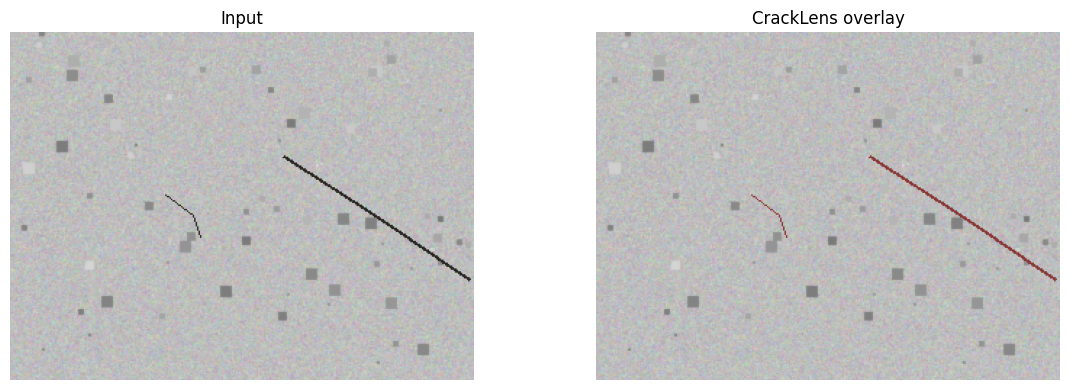

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(Image.open(sample)); axes[0].set_title("Input"); axes[0].axis("off")
axes[1].imshow(result["overlay"]); axes[1].set_title("CrackLens overlay"); axes[1].axis("off")
plt.tight_layout()

## Summary / ?????

**English.** CrackLens produced a reproducible CPU baseline from paired images and masks. The report records the selected grayscale threshold, split-level IoU/F1 metrics, crack length and width estimates, principal-axis angle, flexural/shear screening class, and the configured serviceability verdict. The generated fallback data are a software smoke test; field claims require a calibrated ruler, a public labelled dataset, and validation against engineer-reviewed measurements.

**?????.** CrackLens ?? ?? ???? ???? ????? ???? ?????????? ??????????? ????? ???? ????? ?????? ??? ???? ?? ???? ? ???????? ??? ??? ????? ??????. ????? ??? ???? ????? ?? ???? ?????? ????????? ???? ????? ????????? ????? ? ???? ?????????? ?????? ???? ??????? ???? ??????? ?????? ???? ????? ?????? ???????? ???? ??????????????? ????? ? ??????? ????? ???? ????? ???.